# Visualisation of Contest

### Imports

In [2]:
import os
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
id=600
root="../../../newyorker_caption_contest/data/"

contest_df = pd.read_csv(root+str(id)+".csv")
print(contest_df)

      rank                                            caption      mean  \
0        0  Mission accomplished. We will report that this...  2.998918   
1        1  When I said abduct the dog, I meant President ...  2.068966   
2        2  What is boy? A fire down by the old Jetson's h...  2.062500   
3        3   Did you remember to take him out before we left?  2.060606   
4        4  He agrees to a rectal probe, but only if we us...  2.043478   
...    ...                                                ...       ...   
6038  6038              Sit earthling, sit! Gooood earthling.  1.000000   
6039  6039  You should have gone before we took off. Now y...  1.000000   
6040  6040  I’ve been asking him to take us to his leader ...  1.000000   
6041  6041              so this is their GOD?" "they say DOG.  1.000000   
6042  6042  You say this is the most intelligent life you ...  1.000000   

      precision  votes  not_funny  somewhat_funny  funny  
0      0.001083    924          0       

### Scoring methods

Linkert scale method:

|      Rating    |  Score |
| :-------------:| :----: |
| not funny      |  +1    |
| somewhat_funny |  +2    |
| funny          |  +3    |

The mean is the Arithmetic mean of all the scores for a specific caption $\sum_{i=1}^{n} score_i / n$ where $n$ is the number of votes <br>

The precision is the Standard Error of the Mean (SEM) $\sigma / \sqrt{n}$ where $\sigma$ is the standard deviation of the scores $\sigma^2=\frac{1}{n-1}\sum_{i=1}^{n}(mean-score_i)^2$. <br>
1-n ? n?  <br>



The dataframes are already sorted by the mean so we wont change the oreder <br>



## Visulation of the Votes

In [4]:
# Visualisation of tht votes
'''

x = np.arange(len(contest_df))

plt.figure()
#plt.ylim(0, max(contest_df['not_funny']+contest_df['somewhat_funny']+contest_df['funny'])+10)
plt.yscale("log")
plt.bar(x,contest_df['not_funny'], color='green', label='Not funny votes')
plt.bar(x,contest_df['somewhat_funny'], bottom=contest_df['not_funny'],color='red', label='Somewhat funny votes')
plt.bar(x,contest_df['funny'],bottom=(contest_df['not_funny']+contest_df['somewhat_funny']), color='blue', label='funny votes')
plt.title('Distribution of votes')
plt.xlabel('captions')
plt.ylabel('Number of votes')
plt.tight_layout()
plt.legend()
plt.show()
'''

'\n\nx = np.arange(len(contest_df))\n\nplt.figure()\n#plt.ylim(0, max(contest_df[\'not_funny\']+contest_df[\'somewhat_funny\']+contest_df[\'funny\'])+10)\nplt.yscale("log")\nplt.bar(x,contest_df[\'not_funny\'], color=\'green\', label=\'Not funny votes\')\nplt.bar(x,contest_df[\'somewhat_funny\'], bottom=contest_df[\'not_funny\'],color=\'red\', label=\'Somewhat funny votes\')\nplt.bar(x,contest_df[\'funny\'],bottom=(contest_df[\'not_funny\']+contest_df[\'somewhat_funny\']), color=\'blue\', label=\'funny votes\')\nplt.title(\'Distribution of votes\')\nplt.xlabel(\'captions\')\nplt.ylabel(\'Number of votes\')\nplt.tight_layout()\nplt.legend()\nplt.show()\n'

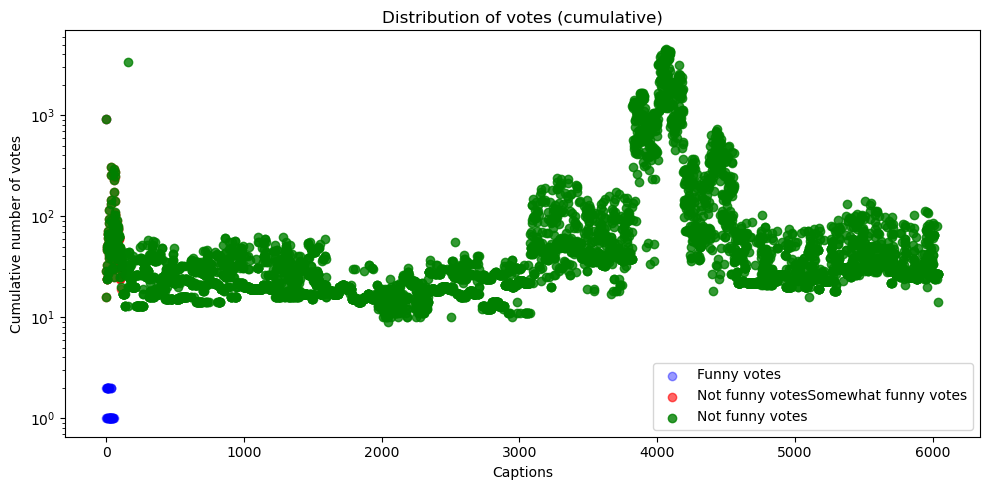

In [5]:
x = np.arange(len(contest_df))

plt.figure(figsize=(10,5))
plt.yscale("log")

# Cumulative scatter stacks (like bars, but with points)
plt.scatter(x, contest_df['funny'], color='blue', label='Funny votes', alpha=0.4)
plt.scatter(x, contest_df['somewhat_funny'] + contest_df['funny'], color='red', label='Not funny votesSomewhat funny votes', alpha=0.6)
plt.scatter(x, contest_df['not_funny'] + contest_df['somewhat_funny']+ contest_df['funny'], color='green', label='Not funny votes', alpha=0.8)


plt.title('Distribution of votes (cumulative)')
plt.xlabel('Captions')
plt.ylabel('Cumulative number of votes')
plt.tight_layout()
plt.legend()
plt.show()


### Divise into 3

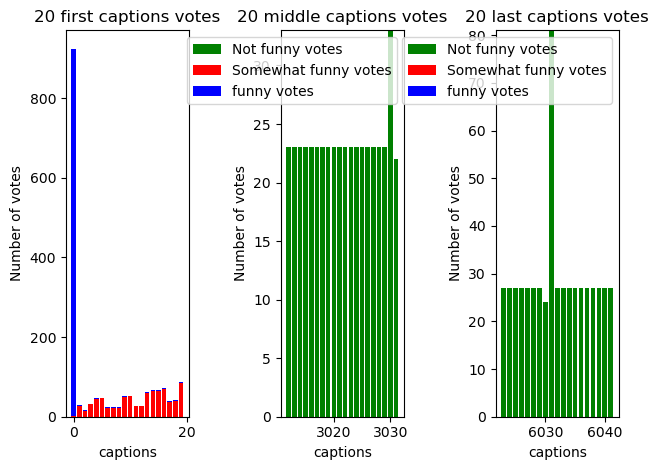

In [6]:
length=len(contest_df)
n_captions=20
first_20=contest_df.iloc[0:n_captions]
mid_20=contest_df.iloc[round(length/2 - n_captions/2):round(length/2 + n_captions/2)]
last_20=contest_df.iloc[-n_captions:-1]

plt.subplot(1,3,1)
#plt.ylim(0, max(contest_df['not_funny']+contest_df['somewhat_funny']+contest_df['funny'])+10)
plt.bar(first_20.index,first_20['not_funny'], color='green', label='Not funny votes')
plt.bar(first_20.index,first_20['somewhat_funny'], bottom=first_20['not_funny'],color='red', label='Somewhat funny votes')
plt.bar(first_20.index,first_20['funny'],bottom=(first_20['not_funny']+first_20['somewhat_funny']), color='blue', label='funny votes')
plt.title('20 first captions votes')
plt.xlabel('captions')
plt.ylabel('Number of votes')
#plt.legend()

plt.subplot(1,3,2)
#plt.ylim(0, max(contest_df['not_funny']+contest_df['somewhat_funny']+contest_df['funny'])+10)
plt.bar(mid_20.index,mid_20['not_funny'], color='green', label='Not funny votes')
plt.bar(mid_20.index,mid_20['somewhat_funny'], bottom=mid_20['not_funny'],color='red', label='Somewhat funny votes')
plt.bar(mid_20.index,mid_20['funny'],bottom=(mid_20['not_funny']+mid_20['somewhat_funny']), color='blue', label='funny votes')
plt.title('20 middle captions votes')
plt.xlabel('captions')
plt.ylabel('Number of votes')
plt.legend()

plt.subplot(1,3,3)
#plt.ylim(0, max(contest_df['not_funny']+contest_df['somewhat_funny']+contest_df['funny'])+10)
plt.bar(last_20.index,last_20['not_funny'], color='green', label='Not funny votes')
plt.bar(last_20.index,last_20['somewhat_funny'], bottom=last_20['not_funny'],color='red', label='Somewhat funny votes')
plt.bar(last_20.index,last_20['funny'],bottom=(last_20['not_funny']+last_20['somewhat_funny']), color='blue', label='funny votes')
plt.title('20 last captions votes')
plt.xlabel('captions')
plt.ylabel('Number of votes')
plt.legend()

plt.tight_layout()
plt.show()

closer look at the middle and last subsample

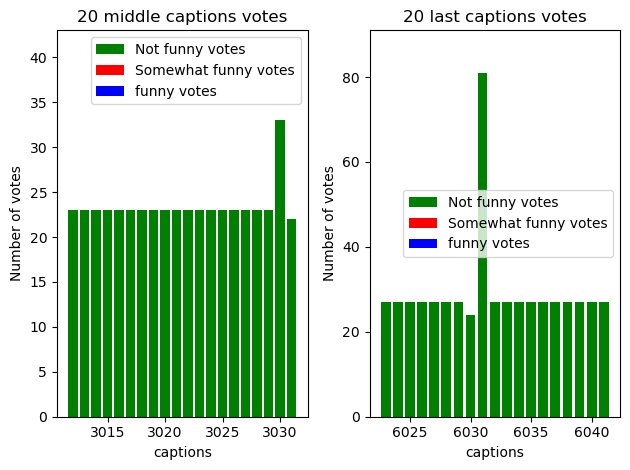

In [7]:
plt.subplot(1,2,1)
plt.ylim(0, max(mid_20['not_funny']+mid_20['somewhat_funny']+mid_20['funny'])+10)
plt.bar(mid_20.index,mid_20['not_funny'], color='green', label='Not funny votes')
plt.bar(mid_20.index,mid_20['somewhat_funny'], bottom=mid_20['not_funny'],color='red', label='Somewhat funny votes')
plt.bar(mid_20.index,mid_20['funny'],bottom=(mid_20['not_funny']+mid_20['somewhat_funny']), color='blue', label='funny votes')
plt.title('20 middle captions votes')
plt.xlabel('captions')
plt.ylabel('Number of votes')
plt.legend()

plt.subplot(1,2,2)
plt.ylim(0, max(last_20['not_funny']+last_20['somewhat_funny']+last_20['funny'])+10)
plt.bar(last_20.index,last_20['not_funny'], color='green', label='Not funny votes')
plt.bar(last_20.index,last_20['somewhat_funny'], bottom=last_20['not_funny'],color='red', label='Somewhat funny votes')
plt.bar(last_20.index,last_20['funny'],bottom=(last_20['not_funny']+last_20['somewhat_funny']), color='blue', label='funny votes')
plt.title('20 last captions votes')
plt.xlabel('captions')
plt.ylabel('Number of votes')
plt.legend()

plt.tight_layout()
plt.show()

Questions, at some point there are no more somewhat funny and fun votes ?

## Means visualisation

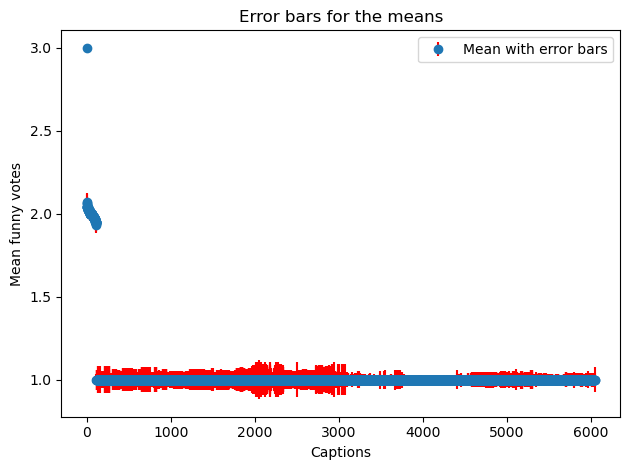

In [8]:

plt.figure()
plt.errorbar(contest_df.index, contest_df['mean'], yerr=contest_df['precision'], fmt='o', ecolor='r', capthick=2,label='Mean with error bars')
plt.title('Error bars for the means')
plt.xlabel('Captions')
plt.ylabel('Mean funny votes')
plt.legend()
plt.tight_layout()
plt.show()


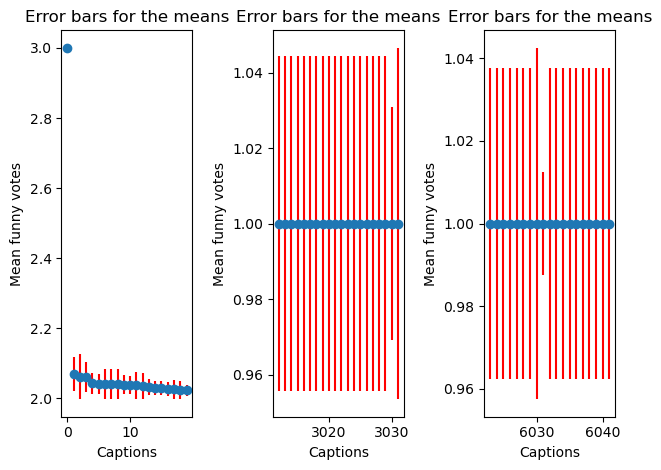

In [9]:
plt.subplot(1,3,1)
plt.errorbar(first_20.index, first_20['mean'], yerr=first_20['precision'], fmt='o', ecolor='r', capthick=2,label='Mean with error bars')
plt.title('Error bars for the means')
plt.xlabel('Captions')
plt.ylabel('Mean funny votes')
plt.tight_layout()

plt.subplot(1,3,2)
plt.errorbar(mid_20.index, mid_20['mean'], yerr=mid_20['precision'], fmt='o', ecolor='r', capthick=2,label='Mean with error bars')
plt.title('Error bars for the means')
plt.xlabel('Captions')
plt.ylabel('Mean funny votes')
plt.tight_layout()


plt.subplot(1,3,3)
plt.errorbar(last_20.index, last_20['mean'], yerr=last_20['precision'], fmt='o', ecolor='r', capthick=2,label='Mean with error bars')
plt.title('Error bars for the means')
plt.xlabel('Captions')
plt.ylabel('Mean funny votes')
plt.tight_layout()
plt.show()

The more we advance in the caption, n is smaller, precision larger, error bars larger, more constant is the mean

Heavy taled dist ?

Regrader le cours pour different graphs 

## Box plots Means

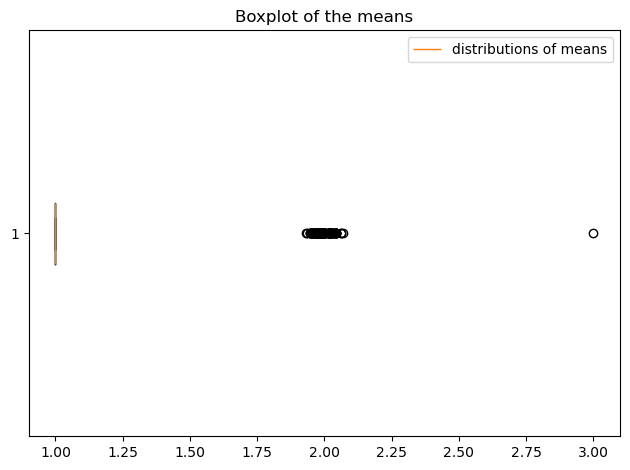

In [10]:
plt.figure()
plt.boxplot(contest_df['mean'],label='distributions of means',orientation='horizontal')
plt.title('Boxplot of the means')
plt.legend()
plt.tight_layout()
plt.show()

## When does the funny votes and somewhat funny votes drop ?

### Overall distribution of the means

/var/folders/mg/6kkx399d74d382844n7gl23r0000gn/T/ipykernel_2776/638788587.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(all_means, labels=labels, vert=False, patch_artist=True)


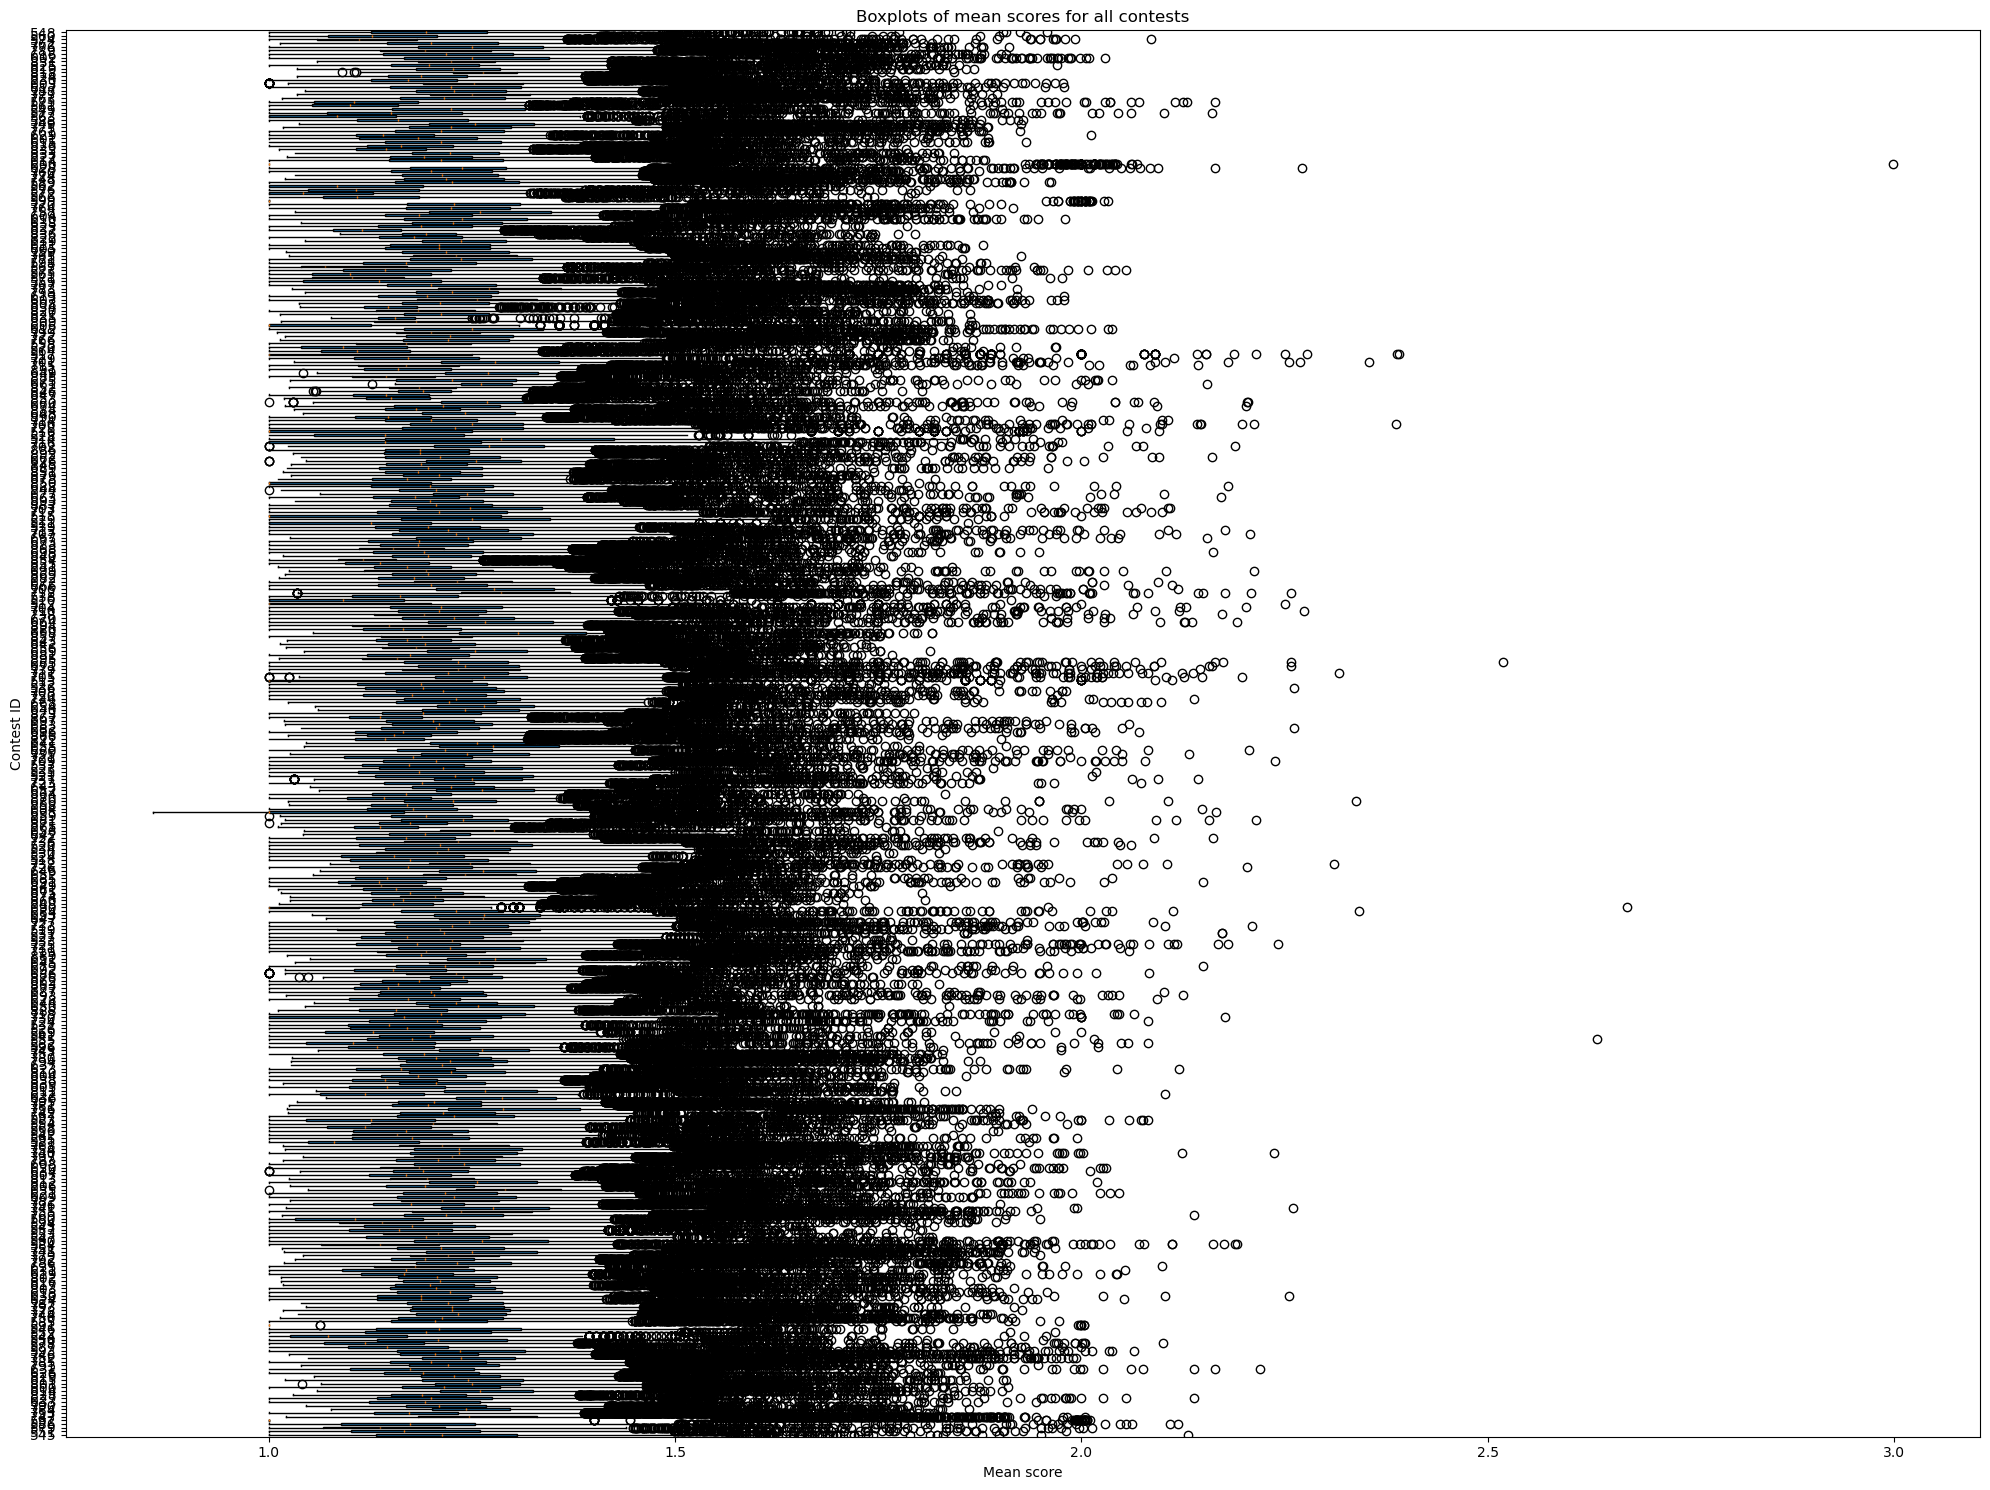

In [13]:
'''
for file in os.listdir(root):
    if file.endswith(".csv"):
        id=file.removesuffix(".csv")
        contest_df = pd.read_csv(root+str(id)+".csv")
        plt.figure(figsize=(20,15))
        plt.boxplot(contest_df['mean'],label=f'contest {id}',orientation='horizontal')
        plt.legend()
plt.title('Boxplot of the means for all contest')
plt.tight_layout()
plt.show()
'''
        
all_means = []
labels = []

# Collect all means
for file in os.listdir(root):
    if file.endswith(".csv"):
        contest_id = file.removesuffix(".csv")
        contest_df = pd.read_csv(os.path.join(root, file))
        all_means.append(contest_df['mean'].dropna())
        labels.append(f'{contest_id}')

# Plot all at once
plt.figure(figsize=(20, 15))
plt.boxplot(all_means, labels=labels, vert=False, patch_artist=True)
plt.title('Boxplots of mean scores for all contests')
plt.xlabel('Mean score')
plt.ylabel('Contest ID')
plt.tight_layout()
plt.show()

/var/folders/mg/6kkx399d74d382844n7gl23r0000gn/T/ipykernel_2776/2499558008.py:12: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(data=full_df, x='mean', y='contest_id', scale='width', inner='quartile')


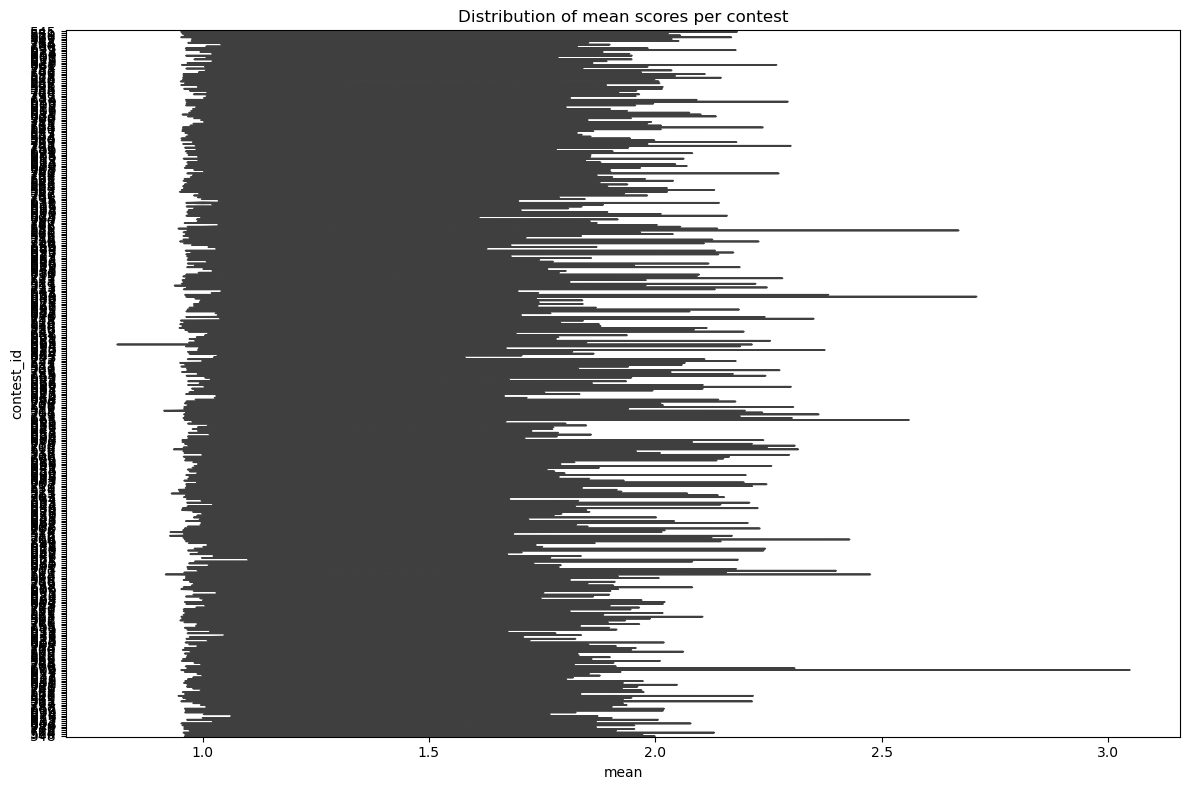

In [15]:
dfs = []
for file in os.listdir(root):
    if file.endswith(".csv"):
        contest_id = file.removesuffix(".csv")
        df = pd.read_csv(os.path.join(root, file))
        df['contest_id'] = contest_id
        dfs.append(df)

full_df = pd.concat(dfs)

plt.figure(figsize=(12, 8))
sns.violinplot(data=full_df, x='mean', y='contest_id', scale='width', inner='quartile')
plt.title("Distribution of mean scores per contest")
plt.tight_layout()
plt.show()